In [1]:

# a. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD


In [25]:

# b. Load MNIST dataset from laptop
data = pd.read_csv(r"D:\Downloads\DL DATASET\MNIST\mnist_784_csv.csv")



In [31]:
# Separate pixels and labels
X = data.drop('class', axis=1).values
y = data['class'].values

In [32]:
# Normalize pixel values
X = X / 255.0

In [33]:
# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [34]:
# c. Define Feedforward Neural Network
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [35]:
# d. Compile and train using SGD
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [36]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8058 - loss: 0.7396 - val_accuracy: 0.8986 - val_loss: 0.3689
Epoch 2/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9085 - loss: 0.3261 - val_accuracy: 0.9168 - val_loss: 0.2941
Epoch 3/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9220 - loss: 0.2714 - val_accuracy: 0.9274 - val_loss: 0.2531
Epoch 4/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9326 - loss: 0.2368 - val_accuracy: 0.9323 - val_loss: 0.2321
Epoch 5/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9397 - loss: 0.2109 - val_accuracy: 0.9386 - val_loss: 0.2094
Epoch 6/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9457 - loss: 0.1901 - val_accuracy: 0.9456 - val_loss: 0.1931
Epoch 7/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9507 - loss: 0.1730 - val_accuracy: 0.9471 - val_loss: 0.1824
Epoch 8/10
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9546 - loss: 0.1584 -

In [37]:
# e. Evaluate the network
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9549 - loss: 0.1605
Test Loss: 0.16052380204200745
Test Accuracy: 0.9548571705818176


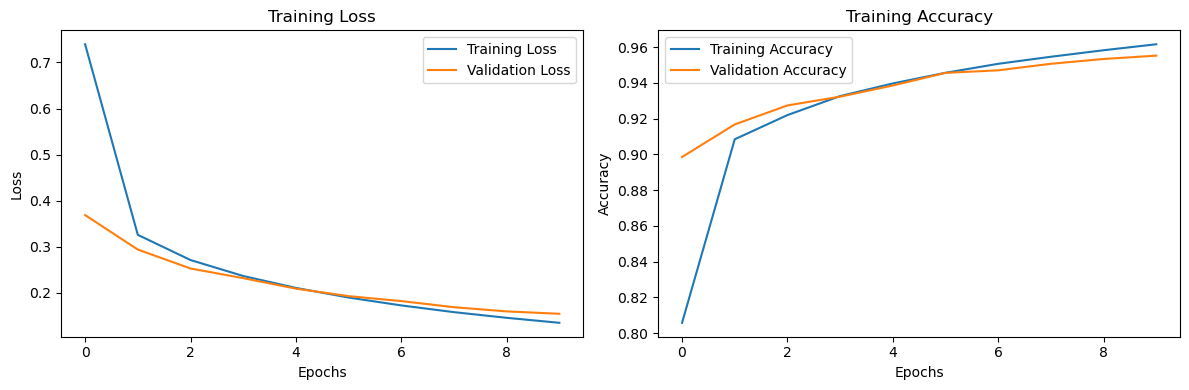

In [39]:
# f. Plot training loss and accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


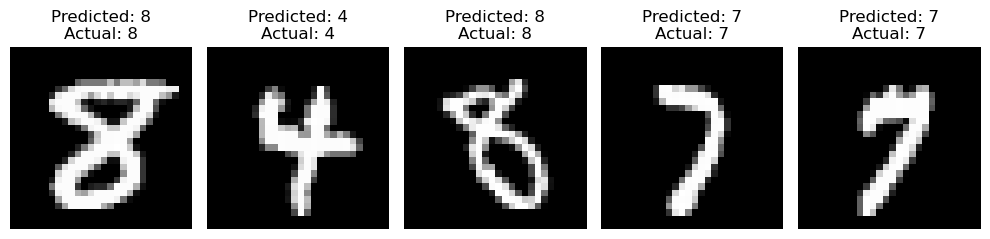

In [38]:
# Display sample digit predictions
predictions = model.predict(X_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {predicted_labels[i]}\nActual: {y_test[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()
